<a href="https://colab.research.google.com/github/goswamijenya-bit/Applied-Data-Science-1/blob/main/Assignment_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
df = pd.read_csv("/content/sample_data/2.Raw_cafe_sales Assignment 1.csv")

print(df.head())      # show the first 5 rows to see what the data looks like
df.info()             # list each column's data type and count of non-empty values
print(df.isna().sum())  # count truly empty (NaN) cells in each column

  Transaction ID    Item Quantity Price Per Unit Total Spent  Payment Method  \
0    TXN_1961373  Coffee        2              2           4     Credit Card   
1    TXN_4977031    Cake        4              3          12            Cash   
2    TXN_4271903  Cookie        4              1       ERROR     Credit Card   
3    TXN_7034554   Salad        2              5          10         UNKNOWN   
4    TXN_3160411  Coffee        2              2           4  Digital Wallet   

   Location Transaction Date  
0  Takeaway         8/9/2023  
1  In-store        16/5/2023  
2  In-store        19/7/2023  
3   UNKNOWN        27/4/2023  
4  In-store        11/6/2023  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   obj

In [2]:
# value_counts() lists every distinct value and how often it appears.
# dropna=False also counts empty (NaN) cells instead of hiding them.
print(df["Payment Method"].value_counts(dropna=False))
print(df["Location"].value_counts(dropna=False))
print(df["Quantity"].value_counts(dropna=False))
print(df["Price Per Unit"].value_counts(dropna=False))

Payment Method
NaN               2579
Digital Wallet    2291
Credit Card       2273
Cash              2258
ERROR              306
UNKNOWN            293
Name: count, dtype: int64
Location
NaN         3265
Takeaway    3022
In-store    3017
ERROR        358
UNKNOWN      338
Name: count, dtype: int64
Quantity
5          2013
2          1974
4          1863
3          1849
1          1822
UNKNOWN     171
ERROR       170
NaN         138
Name: count, dtype: int64
Price Per Unit
3          2429
4          2331
2          1227
5          1204
1          1143
1.5        1133
ERROR       190
NaN         179
UNKNOWN     164
Name: count, dtype: int64


In [3]:
# Count all three kinds of bad values in every column:
# NaN (empty), "ERROR" and "UNKNOWN"
audit = pd.DataFrame({
    "NaN": df.isna().sum(),
    "ERROR": (df == "ERROR").sum(),
    "UNKNOWN": (df == "UNKNOWN").sum()
})

# Total unusable values and what percentage of the 10,000 rows that is
audit["Total bad"] = audit["NaN"] + audit["ERROR"] + audit["UNKNOWN"]
audit["Bad %"] = (audit["Total bad"] / len(df) * 100).round(1)

print(audit.sort_values("Bad %", ascending=False))

# Check for duplicates
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Transaction IDs:", df["Transaction ID"].duplicated().sum())

                   NaN  ERROR  UNKNOWN  Total bad  Bad %
Location          3265    358      338       3961   39.6
Payment Method    2579    306      293       3178   31.8
Item               333    292      344        969    9.7
Price Per Unit     179    190      164        533    5.3
Total Spent        173    164      165        502    5.0
Quantity           138    170      171        479    4.8
Transaction Date   159    142      159        460    4.6
Transaction ID       0      0        0          0    0.0

Duplicate rows: 0
Duplicate Transaction IDs: 0


In [4]:
import numpy as np

# Work on a copy so the raw data stays untouched
df_clean = df.copy()

# 1. Treat ERROR / UNKNOWN as missing values
df_clean = df_clean.replace(["ERROR", "UNKNOWN"], np.nan)

# 2. Convert numeric columns from text to numbers
for col in ["Quantity", "Price Per Unit", "Total Spent"]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# 3. Convert the date column (format in the file is day/month/year)
df_clean["Transaction Date"] = pd.to_datetime(
    df_clean["Transaction Date"], format="%d/%m/%Y", errors="coerce"
)

# Check the result
df_clean.info()
print(df_clean.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    10000 non-null  object        
 1   Item              9031 non-null   object        
 2   Quantity          9521 non-null   float64       
 3   Price Per Unit    9467 non-null   float64       
 4   Total Spent       9498 non-null   float64       
 5   Payment Method    6822 non-null   object        
 6   Location          6039 non-null   object        
 7   Transaction Date  9540 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), object(4)
memory usage: 625.1+ KB
Transaction ID         0
Item                 969
Quantity             479
Price Per Unit       533
Total Spent          502
Payment Method      3178
Location            3961
Transaction Date     460
dtype: int64


In [5]:
# Rule 1: does each item have exactly one price? (menu check)
menu_check = (df_clean.dropna(subset=["Item", "Price Per Unit"])
                      .groupby("Item")["Price Per Unit"]
                      .agg(["nunique", "min", "max"]))
print(menu_check)

# Rule 2: does Total = Quantity x Price on rows where all three are known?
complete = df_clean.dropna(subset=["Quantity", "Price Per Unit", "Total Spent"])
mismatch = (complete["Quantity"] * complete["Price Per Unit"] != complete["Total Spent"]).sum()
print("\nComplete rows checked:", len(complete))
print("Rows where Total != Quantity x Price:", mismatch)

          nunique  min  max
Item                       
Cake            1  3.0  3.0
Coffee          1  2.0  2.0
Cookie          1  1.0  1.0
Juice           1  3.0  3.0
Salad           1  5.0  5.0
Sandwich        1  4.0  4.0
Smoothie        1  4.0  4.0
Tea             1  1.5  1.5

Complete rows checked: 8544
Rows where Total != Quantity x Price: 0


In [6]:
# Build the menu: item -> price (rule 1 showed each item has one price)
menu = (df_clean.dropna(subset=["Item", "Price Per Unit"])
                .groupby("Item")["Price Per Unit"].first().to_dict())

# Prices that belong to only ONE item can identify a missing item
price_counts = pd.Series(menu).value_counts()
unique_price_to_item = {p: i for i, p in menu.items() if price_counts[p] == 1}

print("Missing BEFORE recovery:")
print(df_clean[["Item", "Quantity", "Price Per Unit", "Total Spent"]].isna().sum())

# 1. Price from Item
m = df_clean["Price Per Unit"].isna() & df_clean["Item"].notna()
df_clean.loc[m, "Price Per Unit"] = df_clean.loc[m, "Item"].map(menu)

# 2. Item from Price (only when the price is unique to one item)
m = df_clean["Item"].isna() & df_clean["Price Per Unit"].isin(unique_price_to_item)
df_clean.loc[m, "Item"] = df_clean.loc[m, "Price Per Unit"].map(unique_price_to_item)

# 3. Total = Quantity x Price
m = df_clean["Total Spent"].isna() & df_clean["Quantity"].notna() & df_clean["Price Per Unit"].notna()
df_clean.loc[m, "Total Spent"] = df_clean.loc[m, "Quantity"] * df_clean.loc[m, "Price Per Unit"]

# 4. Quantity = Total / Price
m = df_clean["Quantity"].isna() & df_clean["Total Spent"].notna() & df_clean["Price Per Unit"].notna()
df_clean.loc[m, "Quantity"] = df_clean.loc[m, "Total Spent"] / df_clean.loc[m, "Price Per Unit"]

# 5. Price = Total / Quantity, then try Item again
m = df_clean["Price Per Unit"].isna() & df_clean["Total Spent"].notna() & df_clean["Quantity"].notna()
df_clean.loc[m, "Price Per Unit"] = df_clean.loc[m, "Total Spent"] / df_clean.loc[m, "Quantity"]
m = df_clean["Item"].isna() & df_clean["Price Per Unit"].isin(unique_price_to_item)
df_clean.loc[m, "Item"] = df_clean.loc[m, "Price Per Unit"].map(unique_price_to_item)

print("\nMissing AFTER recovery:")
print(df_clean[["Item", "Quantity", "Price Per Unit", "Total Spent"]].isna().sum())

Missing BEFORE recovery:
Item              969
Quantity          479
Price Per Unit    533
Total Spent       502
dtype: int64

Missing AFTER recovery:
Item              480
Quantity           23
Price Per Unit      6
Total Spent        23
dtype: int64


In [7]:
rows_before = len(df_clean)

# 1. Drop rows still missing a core transaction field
core_cols = ["Item", "Quantity", "Price Per Unit", "Total Spent"]
df_clean = df_clean.dropna(subset=core_cols).copy()
print("Rows dropped:", rows_before - len(df_clean))

# 2. Keep Payment Method / Location as an explicit "Unknown" category (not guessed)
df_clean["Payment Method"] = df_clean["Payment Method"].fillna("Unknown")
df_clean["Location"] = df_clean["Location"].fillna("Unknown")

# 3. Sanity checks, and make Quantity a whole number
mismatch = (df_clean["Quantity"] * df_clean["Price Per Unit"] != df_clean["Total Spent"]).sum()
print("Rows where Total != Quantity x Price:", mismatch)
df_clean["Quantity"] = df_clean["Quantity"].astype(int)

# 4. Date features for the time analysis (missing dates stay NaT)
df_clean["Month"] = df_clean["Transaction Date"].dt.month
df_clean["Month Name"] = df_clean["Transaction Date"].dt.strftime("%b")
df_clean["Weekday"] = df_clean["Transaction Date"].dt.day_name()

print("\nRows kept:", len(df_clean), f"({len(df_clean) / rows_before:.1%} of original)")
print(df_clean.isna().sum())
df_clean.head()

Rows dropped: 500
Rows where Total != Quantity x Price: 0

Rows kept: 9500 (95.0% of original)
Transaction ID        0
Item                  0
Quantity              0
Price Per Unit        0
Total Spent           0
Payment Method        0
Location              0
Transaction Date    436
Month               436
Month Name          436
Weekday             436
dtype: int64


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Month,Month Name,Weekday
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08,9.0,Sep,Friday
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16,5.0,May,Tuesday
2,TXN_4271903,Cookie,4,1.0,4.0,Credit Card,In-store,2023-07-19,7.0,Jul,Wednesday
3,TXN_7034554,Salad,2,5.0,10.0,Unknown,Unknown,2023-04-27,4.0,Apr,Thursday
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11,6.0,Jun,Sunday


In [8]:
num_cols = ["Quantity", "Price Per Unit", "Total Spent"]

# 1. Core descriptive statistics
summary = df_clean[num_cols].agg(["mean", "median", "std", "min", "max", "skew"]).round(2)
print(summary)

# 2. Total revenue
print("\nTotal revenue: $", df_clean["Total Spent"].sum())

# 3. Outliers in Total Spent using the IQR rule
q1, q3 = df_clean["Total Spent"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df_clean[(df_clean["Total Spent"] < low) | (df_clean["Total Spent"] > high)]
print(f"Outlier bounds: {low:.2f} to {high:.2f} | outliers: {len(outliers)}")
print("Largest value:", df_clean["Total Spent"].max())

# 4. Summary per item
by_item = (df_clean.groupby("Item")
           .agg(transactions=("Transaction ID", "count"),
                units=("Quantity", "sum"),
                revenue=("Total Spent", "sum"),
                avg_spend=("Total Spent", "mean"),
                price=("Price Per Unit", "first"))
           .sort_values("revenue", ascending=False)
           .round(2))
by_item["revenue_share_%"] = (by_item["revenue"] / by_item["revenue"].sum() * 100).round(1)
print()
print(by_item)

        Quantity  Price Per Unit  Total Spent
mean        3.02            2.92         8.84
median      3.00            3.00         7.50
std         1.42            1.30         6.03
min         1.00            1.00         1.00
max         5.00            5.00        25.00
skew       -0.00            0.06         0.86

Total revenue: $ 83955.0
Outlier bounds: -8.00 to 24.00 | outliers: 268
Largest value: 25.0

          transactions  units  revenue  avg_spend  price  revenue_share_%
Item                                                                     
Salad             1270   3819  19095.0      15.04    5.0             22.7
Sandwich          1127   3429  13716.0      12.17    4.0             16.3
Smoothie          1094   3336  13344.0      12.20    4.0             15.9
Juice             1168   3505  10515.0       9.00    3.0             12.5
Cake              1138   3468  10404.0       9.14    3.0             12.4
Coffee            1286   3904   7808.0       6.07    2.0          

In [9]:
from scipy import stats

# 1. Correlation matrix
print(df_clean[num_cols].corr().round(3))

# 2. Monthly revenue and a trend test (rows with a missing date are left out)
monthly = df_clean.dropna(subset=["Month"]).groupby("Month")["Total Spent"].sum()
print("\nMonthly revenue:")
print(monthly)
trend = stats.linregress(monthly.index, monthly.values)
print(f"Trend slope: {trend.slope:.1f} per month | p-value: {trend.pvalue:.3f}")

# 3. Do groups differ in spend? (Unknown categories excluded)
known_loc = df_clean[df_clean["Location"] != "Unknown"]
known_pay = df_clean[df_clean["Payment Method"] != "Unknown"]

item_p = stats.kruskal(*[g["Total Spent"] for _, g in df_clean.groupby("Item")]).pvalue
loc_p = stats.mannwhitneyu(
    known_loc.loc[known_loc["Location"] == "In-store", "Total Spent"],
    known_loc.loc[known_loc["Location"] == "Takeaway", "Total Spent"]).pvalue
pay_p = stats.kruskal(*[g["Total Spent"] for _, g in known_pay.groupby("Payment Method")]).pvalue

print(f"\nSpend by item     p = {item_p:.4f}")
print(f"Spend by location p = {loc_p:.3f}")
print(f"Spend by payment  p = {pay_p:.3f}")

                Quantity  Price Per Unit  Total Spent
Quantity           1.000           0.006        0.695
Price Per Unit     0.006           1.000        0.654
Total Spent        0.695           0.654        1.000

Monthly revenue:
Month
1.0     6918.0
2.0     6178.0
3.0     6908.0
4.0     6743.0
5.0     6506.5
6.0     6874.0
7.0     6559.5
8.0     6589.5
9.0     6437.0
10.0    7040.0
11.0    6650.0
12.0    6638.0
Name: Total Spent, dtype: float64
Trend slope: 1.7 per month | p-value: 0.936

Spend by item     p = 0.0000
Spend by location p = 0.065
Spend by payment  p = 0.666


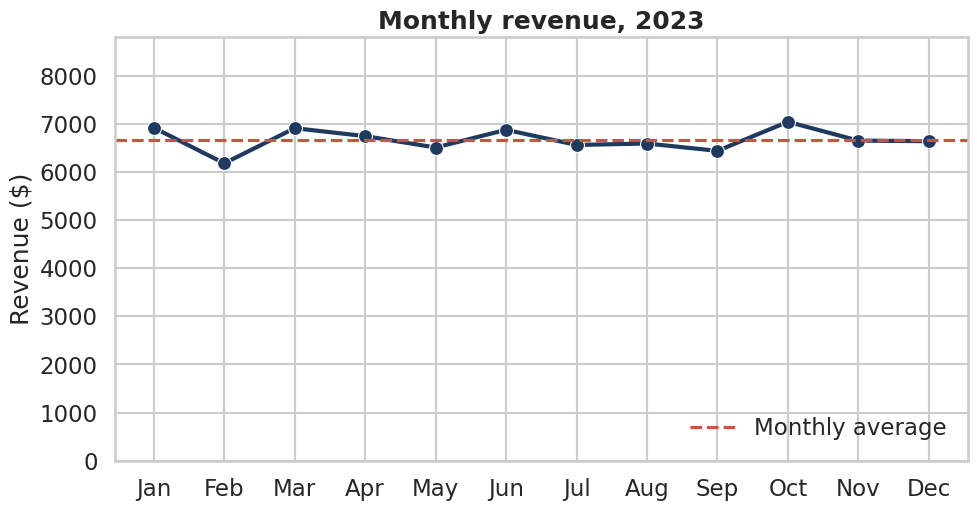

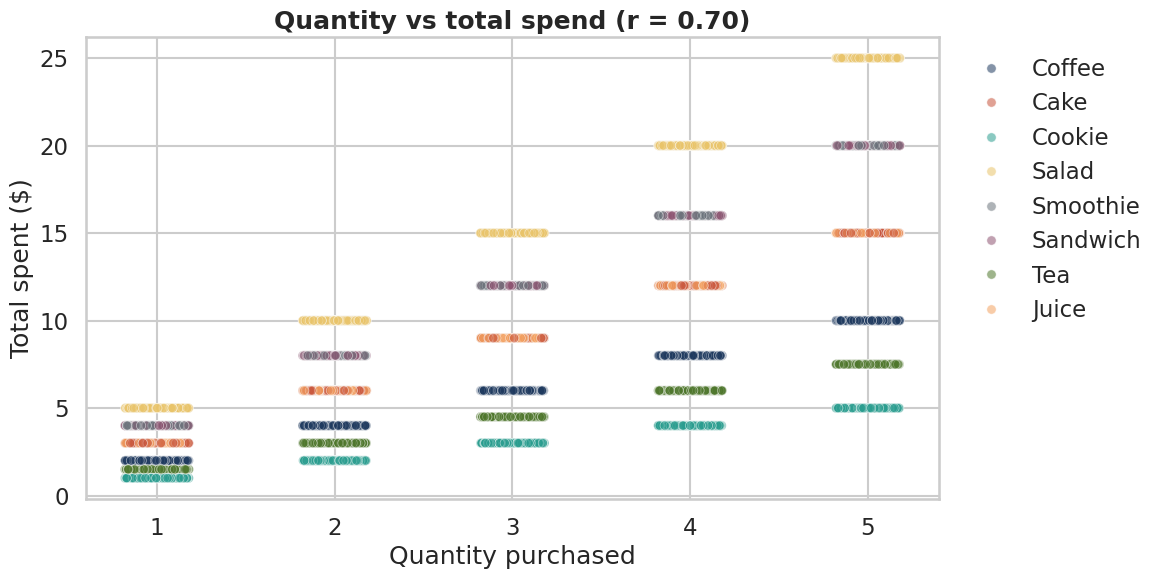

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ---------- Chart style and helper ----------
PALETTE = ["#1F3A5F", "#C8553D", "#2A9D8F", "#E9C46A", "#6C757D", "#8E5572", "#4F772D", "#F4A261"]
sns.set_theme(style="whitegrid", context="talk", palette=PALETTE)
plt.rcParams.update({"savefig.bbox": "tight", "axes.titleweight": "bold"})

FIG_DIR = Path("figures")

def save_and_show(fig, name):
    """Save the figure into the figures folder, then display it."""
    FIG_DIR.mkdir(exist_ok=True)
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()
    plt.close(fig)


# ---------- Relational plot 1: revenue over time ----------
def plot_monthly_revenue(data):
    """Line plot of total revenue for each month of 2023."""
    monthly = (data.dropna(subset=["Month"])
                   .groupby(["Month", "Month Name"], as_index=False)["Total Spent"].sum()
                   .sort_values("Month"))
    fig, ax = plt.subplots(figsize=(11, 5.5))
    sns.lineplot(data=monthly, x="Month Name", y="Total Spent", marker="o",
                 linewidth=3, markersize=10, color=PALETTE[0], ax=ax, sort=False)
    ax.axhline(monthly["Total Spent"].mean(), ls="--", color=PALETTE[1], label="Monthly average")
    ax.set(title="Monthly revenue, 2023", xlabel="", ylabel="Revenue ($)")
    ax.set_ylim(0, monthly["Total Spent"].max() * 1.25)   # start at zero so small changes are not exaggerated
    ax.legend(frameon=False, loc="lower right")
    save_and_show(fig, "relational_monthly_revenue")


# ---------- Relational plot 2: quantity vs total spend ----------
def plot_quantity_vs_total(data):
    """Scatter plot of quantity against total spend, coloured by item."""
    rng = np.random.default_rng(42)
    plot_data = data.copy()
    plot_data["Quantity (jittered)"] = plot_data["Quantity"] + rng.uniform(-0.18, 0.18, len(plot_data))
    r = data["Quantity"].corr(data["Total Spent"])

    fig, ax = plt.subplots(figsize=(11, 6))
    sns.scatterplot(data=plot_data, x="Quantity (jittered)", y="Total Spent", hue="Item",
                    alpha=0.55, s=45, palette=PALETTE, ax=ax)
    ax.set(title=f"Quantity vs total spend (r = {r:.2f})",
           xlabel="Quantity purchased", ylabel="Total spent ($)")
    ax.set_xticks(sorted(data["Quantity"].unique()))
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
    save_and_show(fig, "relational_quantity_vs_total")


plot_monthly_revenue(df_clean)
plot_quantity_vs_total(df_clean)

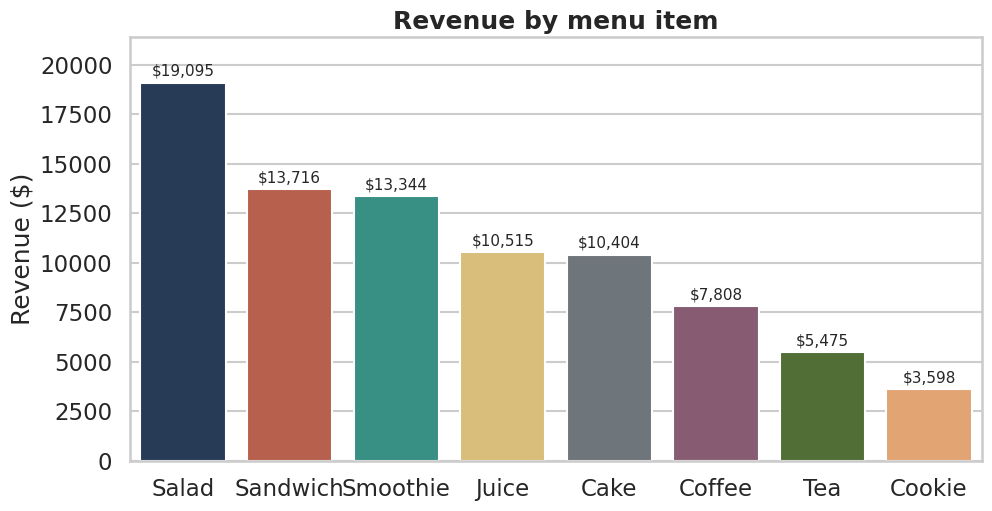

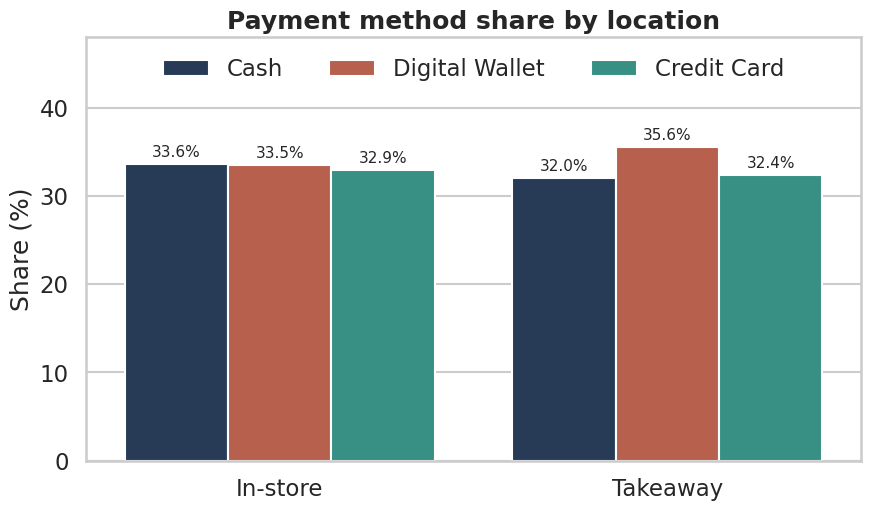

In [11]:
# ---------- Categorical plot 1: revenue by item ----------
def plot_revenue_by_item(data):
    """Bar chart of total revenue for each menu item, ranked."""
    rev = (data.groupby("Item", as_index=False)["Total Spent"].sum()
               .sort_values("Total Spent", ascending=False))
    fig, ax = plt.subplots(figsize=(11, 5.5))
    sns.barplot(data=rev, x="Item", y="Total Spent", hue="Item",
                palette=PALETTE, legend=False, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt="${:,.0f}", padding=3, fontsize=11)   # value label on each bar
    ax.set(title="Revenue by menu item", xlabel="", ylabel="Revenue ($)")
    ax.set_ylim(0, rev["Total Spent"].max() * 1.12)               # leave room for the labels
    save_and_show(fig, "categorical_revenue_by_item")


# ---------- Categorical plot 2: payment method by location ----------
def plot_payment_by_location(data):
    """Grouped bars: share of each payment method within each location (known values only)."""
    known = data[(data["Payment Method"] != "Unknown") & (data["Location"] != "Unknown")]
    share = (known.groupby("Location")["Payment Method"]
                  .value_counts(normalize=True)
                  .mul(100).rename("Share (%)").reset_index())
    fig, ax = plt.subplots(figsize=(10, 5.5))
    sns.barplot(data=share, x="Location", y="Share (%)", hue="Payment Method",
                palette=PALETTE[:3], ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f%%", padding=3, fontsize=11)
    ax.set(title="Payment method share by location", xlabel="", ylim=(0, 48))
    ax.legend(frameon=False, title="", ncol=3, loc="upper center")
    save_and_show(fig, "categorical_payment_by_location")


plot_revenue_by_item(df_clean)
plot_payment_by_location(df_clean)

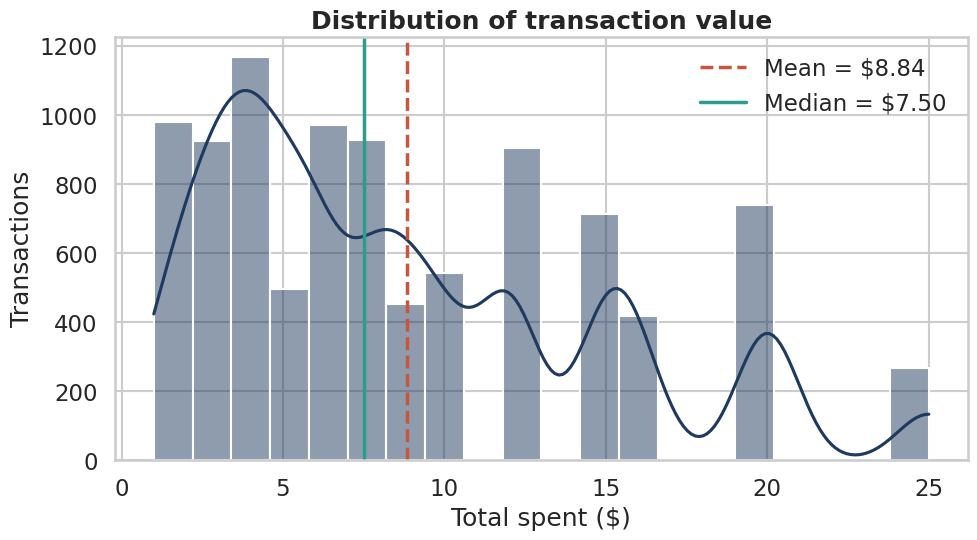

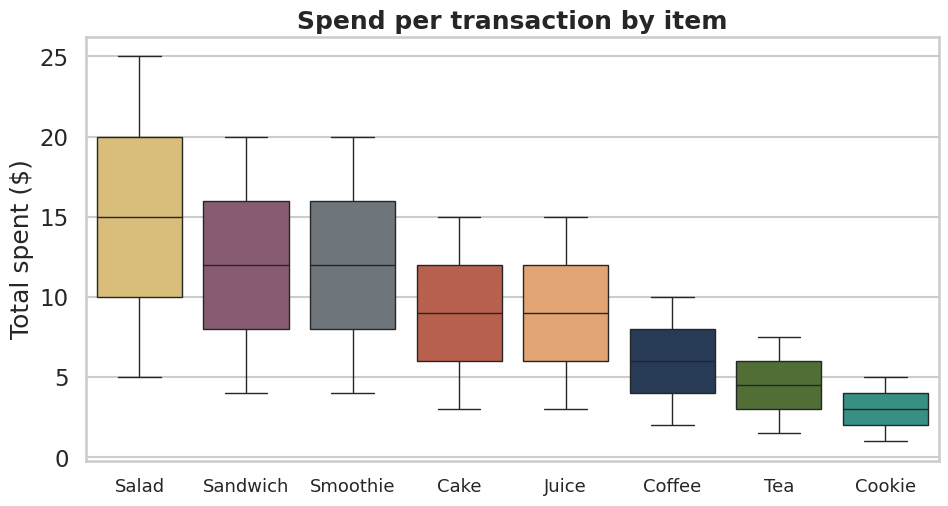

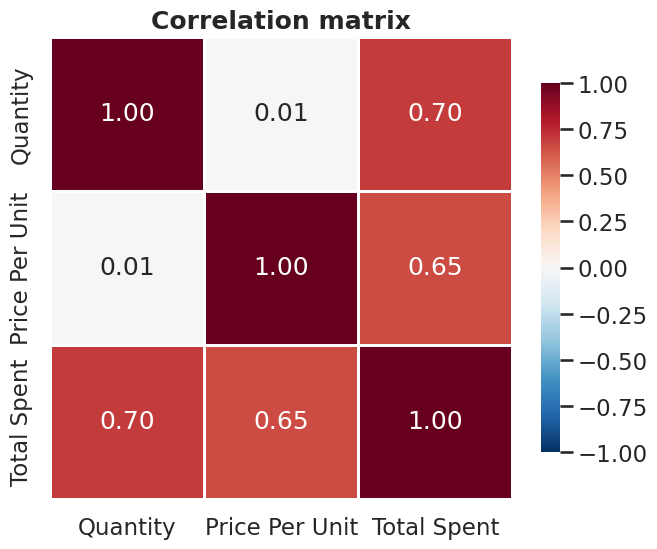

In [12]:
# ---------- Statistical plot 1: distribution of transaction value ----------
def plot_spend_distribution(data):
    """Histogram + density curve of Total Spent, with mean and median marked."""
    mean_val = data["Total Spent"].mean()
    median_val = data["Total Spent"].median()

    fig, ax = plt.subplots(figsize=(11, 5.5))
    sns.histplot(data["Total Spent"], bins=20, kde=True, color=PALETTE[0], ax=ax)
    ax.axvline(mean_val, color=PALETTE[1], ls="--", lw=2.5, label=f"Mean = ${mean_val:.2f}")
    ax.axvline(median_val, color=PALETTE[2], lw=2.5, label=f"Median = ${median_val:.2f}")
    ax.set(title="Distribution of transaction value", xlabel="Total spent ($)", ylabel="Transactions")
    ax.legend(frameon=False)
    save_and_show(fig, "statistical_spend_distribution")


# ---------- Statistical plot 2: spend by item ----------
def plot_spend_boxplot_by_item(data):
    """Box plot of Total Spent for each item, ordered by median."""
    order = data.groupby("Item")["Total Spent"].median().sort_values(ascending=False).index
    fig, ax = plt.subplots(figsize=(11, 5.5))
    sns.boxplot(data=data, x="Item", y="Total Spent", order=order, hue="Item",
                palette=PALETTE, legend=False, ax=ax)
    ax.set(title="Spend per transaction by item", xlabel="", ylabel="Total spent ($)")
    ax.tick_params(axis="x", labelsize=13)
    save_and_show(fig, "statistical_spend_boxplot_by_item")


# ---------- Statistical plot 3: correlation heatmap ----------
def plot_correlation_heatmap(data):
    """Heatmap of Pearson correlations between the numeric columns."""
    corr = data[["Quantity", "Price Per Unit", "Total Spent"]].corr()
    fig, ax = plt.subplots(figsize=(7.5, 6))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
                square=True, linewidths=2, cbar_kws={"shrink": 0.8}, ax=ax)
    ax.set_title("Correlation matrix")
    save_and_show(fig, "statistical_correlation_heatmap")


plot_spend_distribution(df_clean)
plot_spend_boxplot_by_item(df_clean)
plot_correlation_heatmap(df_clean)

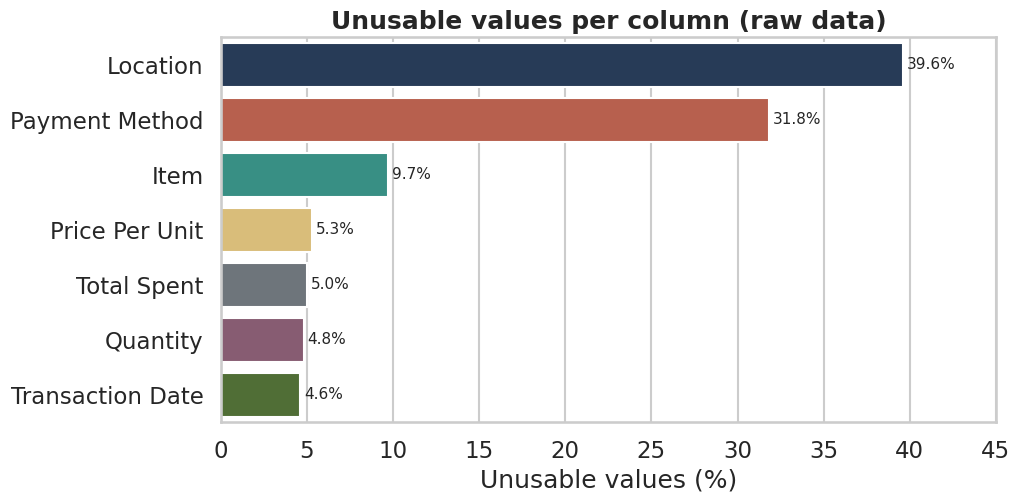

In [13]:
# ---------- Supporting plot: data quality ----------
def plot_data_quality(audit_table):
    """Bar chart of the percentage of unusable values in each raw column."""
    q = (audit_table.drop(index="Transaction ID")          # this column has no bad values
                    .reset_index()
                    .rename(columns={"index": "Column"})
                    .sort_values("Bad %", ascending=False))
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.barplot(data=q, x="Bad %", y="Column", hue="Column",
                palette=PALETTE[:7], legend=False, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f%%", padding=3, fontsize=11)
    ax.set(title="Unusable values per column (raw data)", xlabel="Unusable values (%)",
           ylabel="", xlim=(0, 45))
    save_and_show(fig, "data_quality")


plot_data_quality(audit)

In [14]:
# import shutil
# from google.colab import files

# # Save the cleaned dataset
# df_clean.to_csv("cleaned_cafe_sales.csv", index=False)

# # Zip all the saved charts into one file
# shutil.make_archive("figures", "zip", "figures")

# # Download both to your computer
# files.download("cleaned_cafe_sales.csv")
# files.download("figures.zip")